# GPT-2 + RL на KION



In [3]:
from pathlib import Path
import os
import sys
import json

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/small.json").exists() and (p / "src/recsys_rl").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Откройте блокнот из папки RecSys_rl или её подпапки notebooks")
os.chdir(ROOT)
for folder in (ROOT / "src", ROOT / "scripts"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

RUN_EXPERIMENT = True
DEVICE = "mps"
SMALL_RUN = ROOT
RUN_DIR = ROOT / "experiments/users50k"

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 20)

print("Python ядра:", sys.executable)
print("MPS доступен ядру:", torch.backends.mps.is_available())
print("Режим:", "выполнение" if RUN_EXPERIMENT else "просмотр сохранённых результатов")
print("Эксперимент:", RUN_DIR)

Python ядра: /Users/arina/Documents/Projects/RecSys_feature_engineering/recsys_venv/bin/python
MPS доступен ядру: True
Режим: выполнение
Эксперимент: /Users/arina/Documents/Projects/RecSys_rl/experiments/users50k


## 1. Постановка и данные

Политика предсказывает следующий ID объекта по истории. Reward model оценивает `watched_pct / 100`.

- Train: даты до 2021-07-01; validation: июль; test: с 2021-08-01.
- В истории только события **предыдущих дней**, максимум 64 объекта. Порядок внутри прошедшего дня
  задан по ID: точного времени в данных нет.
- Для 50k сохраняются исходные 10k пользователей и добавляются 40k из train.
- Validation/test и словарь объектов остаются неизменными. Test не используется для выбора моделей.
- Одна цель после контекста; loss по всем соседним позициям создал бы искусственные переходы внутри дня.
- Пропуски отклика исключаются только из обучения reward model, а не заменяются нулём.

In [4]:
from prepare_data import main as prepare_data
from train_baseline import main as train_baseline
from train_reward import main as train_reward
from train_rl import main as train_rl
from final_evaluation import main as final_evaluation

def stage(title, function, arguments, expected):
    expected = [Path(p) for p in expected]
    if all(path.exists() for path in expected):
        print(f"✓ {title}: сохранённые результаты найдены")
    elif not RUN_EXPERIMENT:
        print(f"— {title}: результатов нет; для выполнения установите RUN_EXPERIMENT=True")
    else:
        print(f"▶ {title}")
        function(arguments)
        if not all(path.exists() for path in expected):
            raise RuntimeError(f"Этап не создал ожидаемые файлы: {title}")

def read_json(path):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else None

stage("Подготовка 10k", prepare_data,
      ["--config", "configs/small.json", "--run-dir", str(SMALL_RUN)],
      [SMALL_RUN / "reports/data_audit.json", SMALL_RUN / "artifacts/prepared/train.npz"])
stage("Подготовка 50k с фиксированной оценкой", prepare_data,
      ["--config", "configs/users50k.json", "--run-dir", str(RUN_DIR),
       "--freeze-eval-from", str(SMALL_RUN)],
      [RUN_DIR / "reports/data_audit.json", RUN_DIR / "artifacts/prepared/train.npz"])

small_audit = read_json(SMALL_RUN / "reports/data_audit.json")
audit = read_json(RUN_DIR / "reports/data_audit.json")
rows=[]
for name, data in [("10k", small_audit), ("50k", audit)]:
    if data:
        for split, values in data["prepared"].items():
            rows.append({"experiment": name, "split": split, **values})
display(pd.DataFrame(rows))
if audit:
    display(pd.Series({key: audit[key] for key in
        ["valid_rows", "invalid_date_rows", "missing_reward_rows", "vocabulary_items"]}, name="Аудит"))

✓ Подготовка 10k: сохранённые результаты найдены
✓ Подготовка 50k с фиксированной оценкой: сохранённые результаты найдены


,experiment,split,examples,users,reward_examples,mean_history_length
0,10k,train,50573,10000,50557,5.542285
1,10k,validation,11854,4051,11847,12.349334
2,10k,test,5962,2576,5962,15.475512
3,50k,train,253320,50000,253264,5.801066
4,50k,validation,11854,4051,11847,12.349334
5,50k,test,5962,2576,5962,15.475512


valid_rows             1594786
invalid_date_rows            1
missing_reward_rows        267
vocabulary_items         11028
Name: Аудит, dtype: int64

In [ ]:

import hashlib
checks=[]
for filename in ["validation.npz", "test.npz", "vocabulary.json"]:
    old = SMALL_RUN / "artifacts/prepared" / filename
    new = RUN_DIR / "artifacts/prepared" / filename
    if old.exists() and new.exists():
        same = hashlib.sha256(old.read_bytes()).digest() == hashlib.sha256(new.read_bytes()).digest()
        checks.append({"file": filename, "identical": same})
        assert same, f"Отложенные данные или словарь изменились: {filename}"
display(pd.DataFrame(checks))

,file,identical
0,validation.npz,True
1,test.npz,True
2,vocabulary.json,True


## 2. GPT-2 baseline

Компактный GPT-2 обучается с нуля: 2 слоя, размерность 64, 2 головы внимания, связанная выходная
голова. PAD не участвует в рекомендациях. Checkpoint выбирается по validation NDCG@10.

Recall и NDCG рассчитываются по всему train-каталогу: сначала среднее по событиям пользователя,
затем среднее по пользователям. Повторы не маскируются, чтобы анализировать поведение моделей.
Сравнение 10k/50k использует одинаковую оценку, но большая выборка означает больше обновлений в эпохе.

In [6]:
for title, folder, config in [("GPT-2 10k", SMALL_RUN, "configs/small.json"),
                               ("GPT-2 50k", RUN_DIR, "configs/users50k.json")]:
    stage(title, train_baseline, ["--config", config, "--run-dir", str(folder), "--device", DEVICE],
          [folder / "artifacts/baseline/best.pt", folder / "reports/baseline.json"])

baseline_runs = {name: read_json(folder / "reports/baseline.json")
                 for name, folder in [("10k", SMALL_RUN), ("50k", RUN_DIR)]}
comparison=[]
for name, report in baseline_runs.items():
    if report:
        best=max(report["history"], key=lambda row: row["ndcg@10"])
        comparison.append({"experiment": name, **{key: best[key] for key in
            ["epoch", "recall@10", "ndcg@10", "catalog_coverage@10", "cross_entropy"]}})
display(pd.DataFrame(comparison).round(5))

✓ GPT-2 10k: сохранённые результаты найдены
✓ GPT-2 50k: сохранённые результаты найдены


,experiment,epoch,recall@10,ndcg@10,catalog_coverage@10,cross_entropy
0,10k,1,0.17740,0.08454,0.00399,8.04713
1,50k,1,0.16432,0.08704,0.01378,7.74809


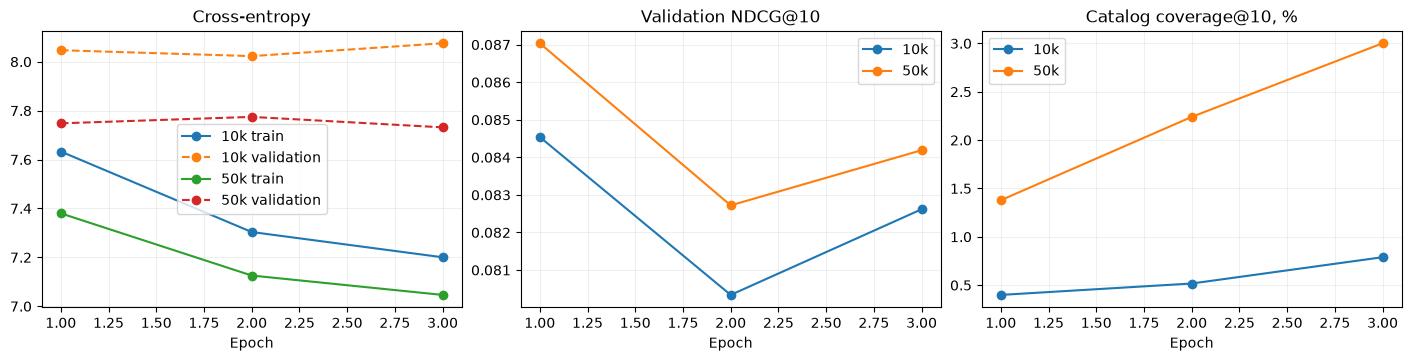

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
for name, report in baseline_runs.items():
    if not report:
        continue
    history=pd.DataFrame(report["history"])
    axes[0].plot(history.epoch, history.train_loss, marker="o", label=f"{name} train")
    axes[0].plot(history.epoch, history.cross_entropy, marker="o", linestyle="--", label=f"{name} validation")
    axes[1].plot(history.epoch, history["ndcg@10"], marker="o", label=name)
    axes[2].plot(history.epoch, 100 * history["catalog_coverage@10"], marker="o", label=name)
for ax, title in zip(axes, ["Cross-entropy", "Validation NDCG@10", "Catalog coverage@10, %"]):
    ax.set(title=title, xlabel="Epoch")
    ax.grid(alpha=.2)
    ax.legend()
plt.show()

## 3. Reward model

Инициализация эмбеддингов — из соответствующего GPT-2. История агрегируется с большим весом
недавних объектов. MLP использует историю, кандидата и их взаимодействия. Нейросетевая поправка
добавляется к сглаженному train-среднему объекта; sigmoid ограничивает выход диапазоном [0, 1].

Checkpoint выбирается по validation RMSE. Контроли — среднее train и сглаженное среднее объекта.
Неизвестный отклик не считается отрицательным. Оценка на исторически выбранных объектах
не гарантирует точность предсказаний для любых новых рекомендаций.

In [8]:
for title, folder in [("Reward model 10k", SMALL_RUN), ("Reward model 50k", RUN_DIR)]:
    stage(title, train_reward, ["--run-dir", str(folder), "--device", DEVICE],
          [folder / "artifacts/reward/best.pt", folder / "reports/reward.json"])

reward_runs={name: read_json(folder / "reports/reward.json")
             for name, folder in [("10k", SMALL_RUN), ("50k", RUN_DIR)]}
reward_rows=[]
for name, report in reward_runs.items():
    if report:
        for model, metrics in {**report["controls_validation"], "reward_model": report["best_validation"]}.items():
            reward_rows.append({"experiment": name, "model": model, **metrics})
display(pd.DataFrame(reward_rows).round(5))

✓ Reward model 10k: сохранённые результаты найдены
✓ Reward model 50k: сохранённые результаты найдены


,experiment,model,mae,rmse,r2,pearson,mean_prediction,mean_observed_reward,examples
0,10k,constant_train_mean,0.39679,0.41911,-0.00161,NaN,0.55190,0.53511,11847
1,10k,smoothed_item_mean,0.37176,0.40216,0.07778,0.28714,0.56115,0.53511,11847
2,10k,reward_model,0.36663,0.39974,0.08885,0.29946,0.54710,0.53511,11847
3,50k,constant_train_mean,0.39677,0.41907,-0.00137,NaN,0.55063,0.53511,11847
4,50k,smoothed_item_mean,0.36222,0.39799,0.09680,0.31885,0.56370,0.53511,11847
5,50k,reward_model,0.35542,0.39584,0.10656,0.34042,0.57229,0.53511,11847


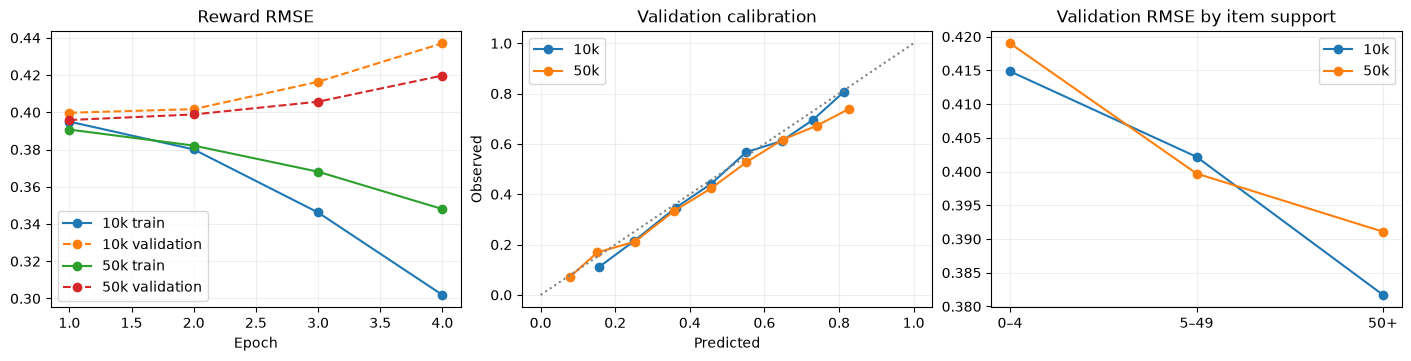

In [9]:
fig, axes=plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
for name, report in reward_runs.items():
    if not report:
        continue
    history=pd.DataFrame(report["history"])
    axes[0].plot(history.epoch, np.sqrt(history.train_mse), marker="o", label=f"{name} train")
    axes[0].plot(history.epoch, history.rmse, marker="o", linestyle="--", label=f"{name} validation")
    bins=pd.DataFrame(report["calibration"])
    axes[1].plot(bins.prediction, bins.observed, marker="o", label=name)
    slices=pd.DataFrame(report["frequency_slices"]).T
    axes[2].plot(range(len(slices)), slices.rmse, marker="o", label=name)
axes[0].set(title="Reward RMSE", xlabel="Epoch")
axes[1].plot([0,1],[0,1],color="gray",linestyle=":")
axes[1].set(title="Validation calibration", xlabel="Predicted", ylabel="Observed")
axes[2].set(title="Validation RMSE by item support", xticks=[0,1,2], xticklabels=["0–4", "5–49", "50+"])
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend()
plt.show()

## 4. RL и контроль дополнительного обучения

Одношаговый REINFORCE оптимизирует

$$J(\theta)=\mathbb{E}_{a\sim\pi_\theta(\cdot\mid h)}[\hat R(h,a)]
-\beta D_{KL}(\pi_\theta\Vert\pi_{ref}).$$

Для каждой истории независимо с возвращением сэмплируются 4 действия. Baseline действия —
средний reward остальных трёх. KL вычисляется по полному каталогу. Reference и reward model
заморожены; dropout policy отключён, градиенты policy включены.

Варианты: исходный reward при β=0.01/0.1/1 и штраф 0.2 за повтор из контекста при β=0.1.
Контроль — продолжение supervised-обучения с тем же learning rate и числом обновлений.
Внутри вариантов checkpoint выбирается по регуляризованной цели с ограничением на NDCG.
Между RL-вариантами — по reward@10 при потере validation NDCG не более 5%.

In [10]:
stage("RL и supervised-контроль", train_rl, ["--run-dir", str(RUN_DIR), "--device", DEVICE],
      [RUN_DIR / "reports/rl.json", RUN_DIR / "artifacts/rl/repeat_kl01/best.pt"])
rl_report=read_json(RUN_DIR / "reports/rl.json")
validation_rows=[]
if rl_report:
    validation_rows.append({"model":"baseline", **rl_report["baseline_validation"]})
    validation_rows.extend({"model":name, **value["selected"]} for name,value in rl_report["variants"].items())
    validation_table=pd.DataFrame(validation_rows).set_index("model")
    display(validation_table[["ndcg@10", "recall@10", "reward@10", "sampled_reward",
                              "kl_to_reference", "catalog_coverage@10"]].round(5))
    print("Основной вариант по validation:", rl_report["recommended_variant"])

✓ RL и supervised-контроль: сохранённые результаты найдены


,ndcg@10,recall@10,reward@10,sampled_reward,kl_to_reference,catalog_coverage@10
model,,,,,,
baseline,0.08704,0.16432,0.59681,0.56223,0.00000,0.01378
sft_control,0.08721,0.16254,0.59948,0.56491,0.00354,0.01442
raw_kl001,0.08472,0.15910,0.64672,0.59519,0.08647,0.01124
raw_kl01,0.08633,0.16151,0.64091,0.59171,0.05674,0.01242
raw_kl1,0.08662,0.16283,0.61930,0.57326,0.00355,0.01415
repeat_kl01,0.08651,0.16141,0.64226,0.59034,0.05397,0.01224


Основной вариант по validation: raw_kl001


## 5. Test без выбора моделей по test

До расчёта фиксируются выбор и контрольные суммы моделей. Test оценивается для baseline и заранее
обученных абляций. Рост reward здесь всё ещё означает рост оценки той же reward model.
Релевантность оценивается отдельно по наблюдаемым next-item целям.

Финальный скрипт сохраняет JSON, массивы предсказаний и PNG-графики. Текстовый отчёт он не создаёт.

In [11]:
stage("Финальная оценка и цепочки", final_evaluation,
      ["--run-dir", str(RUN_DIR), "--device", DEVICE],
      [RUN_DIR / "reports/final_evaluation.json", RUN_DIR / "reports/rollout_examples.json",
       RUN_DIR / "reports/tradeoff.png", RUN_DIR / "reports/rollout.png"])
final=read_json(RUN_DIR / "reports/final_evaluation.json")
if final:
    test_table=pd.DataFrame(final["test"]).T
    columns=["recall@10", "ndcg@10", "reward@10", "sampled_reward", "catalog_coverage@10",
             "catalog_entropy@10", "seen_in_last_context_share@10", "mean_train_popularity@10"]
    display(test_table.reindex(columns=columns).round(5))
    print("Основная модель зафиксирована до test:", final["selection"]["main_rl_variant"])
else:
    print("Финальных результатов пока нет")

✓ Финальная оценка и цепочки: сохранённые результаты найдены


,recall@10,ndcg@10,reward@10,sampled_reward,catalog_coverage@10,catalog_entropy@10,seen_in_last_context_share@10,mean_train_popularity@10
popularity,0.08611,0.04773,NaN,NaN,NaN,NaN,NaN,NaN
baseline,0.09787,0.05363,0.60526,0.56660,0.01288,3.36588,0.11372,10478.77618
sft_control,0.09610,0.05272,0.60823,0.56669,0.01387,3.42135,0.11374,10198.43641
raw_kl001,0.09696,0.05336,0.65436,0.59575,0.01106,3.41930,0.11333,9302.90969
raw_kl01,0.09633,0.05342,0.64902,0.59169,0.01206,3.40892,0.11421,9596.45793
raw_kl1,0.09853,0.05369,0.62760,0.57510,0.01333,3.39231,0.11384,10197.79611
repeat_kl01,0.09636,0.05320,0.65018,0.59055,0.01197,3.42107,0.11380,9485.60934


Основная модель зафиксирована до test: raw_kl001


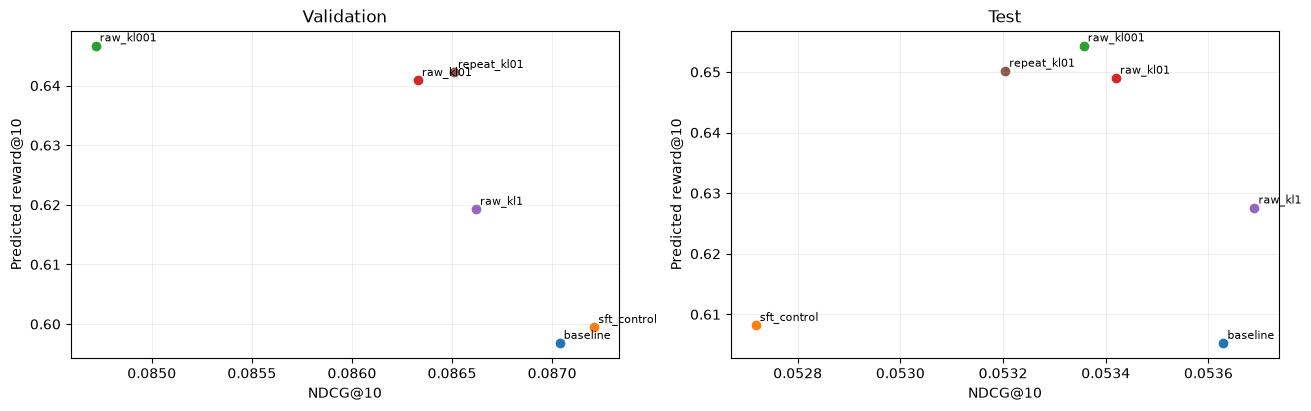

In [12]:
fig,axes=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
for ax, split, rows in [(axes[0], "Validation", validation_rows),
                        (axes[1], "Test", [{"model":name, **row} for name,row in final["test"].items()] if final else [])]:
    for row in rows:
        if "reward@10" not in row:
            continue
        ax.scatter(row["ndcg@10"],row["reward@10"])
        ax.annotate(row["model"],(row["ndcg@10"],row["reward@10"]),xytext=(3,3),textcoords="offset points",fontsize=8)
    ax.set(title=split,xlabel="NDCG@10",ylabel="Predicted reward@10")
    ax.grid(alpha=.2)
plt.show()

## 6. Неопределённость и качество reward на test

Парный bootstrap ресэмплирует пользователей, сохраняя соответствие результатов двух моделей.
95% интервал включает неопределённость по пользователям **при фиксированных обученных весах**,
но не вариативность обучения по seed и не поправку на множественные сравнения.

Интервал, содержащий ноль, не доказывает равенство моделей. Для утверждения «потеря меньше 5%»
нужно отдельно проверить нижнюю границу относительно заранее выбранного порога.
`NaN` reward у popularity означает, что эта метрика для неё не вычислялась.

In [13]:
interval_rows=[]
if final:
    for model, metrics in final["bootstrap"].items():
        for metric, value in metrics.items():
            interval_rows.append({"model":model,"metric":metric,"difference":value["difference"],
                                  "ci_low":value["ci95"][0],"ci_high":value["ci95"][1]})
    intervals=pd.DataFrame(interval_rows)
    display(intervals.round(6))
    display(pd.DataFrame(final["reward_test"]).T.round(5))

    main_model=final["selection"]["main_rl_variant"]
    base=final["test"]["baseline"]
    if main_model:
        chosen=final["test"][main_model]
        display(pd.Series({
            "Δ NDCG, % относительно baseline":100*(chosen["ndcg@10"]/base["ndcg@10"]-1),
            "Δ predicted reward, % относительно baseline":100*(chosen["reward@10"]/base["reward@10"]-1),
            "Δ predicted reward, абсолютная":chosen["reward@10"]-base["reward@10"],
            "Нижняя граница Δ NDCG, %":100*final["bootstrap"][main_model]["ndcg@10"]["ci95"][0]/base["ndcg@10"],
        },name=main_model).round(4))

,model,metric,difference,ci_low,ci_high
0,sft_control,ndcg@10,-0.000911,-0.001967,0.000045
1,sft_control,recall@10,-0.001767,-0.003803,0.000081
2,sft_control,reward@10,0.002964,0.002403,0.003490
3,raw_kl001,ndcg@10,-0.000272,-0.003080,0.002397
4,raw_kl001,recall@10,-0.000905,-0.005508,0.003680
5,raw_kl001,reward@10,0.049100,0.047634,0.050522
6,raw_kl01,ndcg@10,-0.000209,-0.002646,0.002126
7,raw_kl01,recall@10,-0.001538,-0.005759,0.002448
8,raw_kl01,reward@10,0.043763,0.042350,0.045104
9,raw_kl1,ndcg@10,0.000061,-0.001186,0.001243


,mae,rmse,r2,pearson,mean_prediction,mean_observed_reward,examples
constant_train_mean,0.37946,0.40701,-0.06457,NaN,0.55063,0.4504,5962.0
smoothed_item_mean,0.36020,0.39762,-0.01602,0.26702,0.56341,0.4504,5962.0
reward_model,0.35770,0.39958,-0.02605,0.28374,0.57157,0.4504,5962.0


Δ NDCG, % относительно baseline               -0.5071
Δ predicted reward, % относительно baseline    8.1122
Δ predicted reward, абсолютная                 0.0491
Нижняя граница Δ NDCG, %                      -5.7423
Name: raw_kl001, dtype: float64

## 7. Пять рекомендаций вперёд

Для всех моделей одинаковые реальные стартовые истории: по одной на пользователя. В режимах greedy
и sampling каждый выбранный объект добавляется в контекст, хотя реальное взаимодействие неизвестно.

`repeat_generated` — повтор одного из ранее сгенерированных объектов, а не повтор из исходной истории.
`reward_frozen_history` оценивает **тот же выбранный объект** на неизменной исходной истории:
разница с текущим reward показывает чувствительность reward model к синтетическому контексту.

In [14]:
chain_rows=[]
if final:
    for model,modes in final["rollout"].items():
        for mode,value in modes.items():
            chain_rows.append({"model":model,"mode":mode,"reward_step1":value["reward"][0],
                "reward_step5":value["reward"][-1],"reward_step5_frozen":value["reward_frozen_history"][-1],
                "repeat_generated_step5":value["repeat_generated"][-1],
                "unique_items_per_chain":value["mean_unique_items_in_chain"]})
    display(pd.DataFrame(chain_rows).round(5))

,model,mode,reward_step1,reward_step5,reward_step5_frozen,repeat_generated_step5,unique_items_per_chain
0,baseline,greedy,0.68023,0.70773,0.66476,0.91797,1.53125
1,baseline,sample,0.56790,0.58644,0.58248,0.02344,4.95703
2,sft_control,greedy,0.68015,0.71187,0.67103,0.92578,1.45703
3,sft_control,sample,0.57114,0.58447,0.58109,0.01562,4.96484
4,raw_kl001,greedy,0.70556,0.74660,0.71950,0.93359,1.39844
5,raw_kl001,sample,0.60580,0.61943,0.61149,0.01562,4.94922
6,raw_kl01,greedy,0.69917,0.74073,0.71158,0.94141,1.39453
7,raw_kl01,sample,0.59667,0.61655,0.60901,0.01953,4.94531
8,raw_kl1,greedy,0.69396,0.72108,0.68317,0.94141,1.44531
9,raw_kl1,sample,0.57926,0.59141,0.58654,0.02344,4.95312


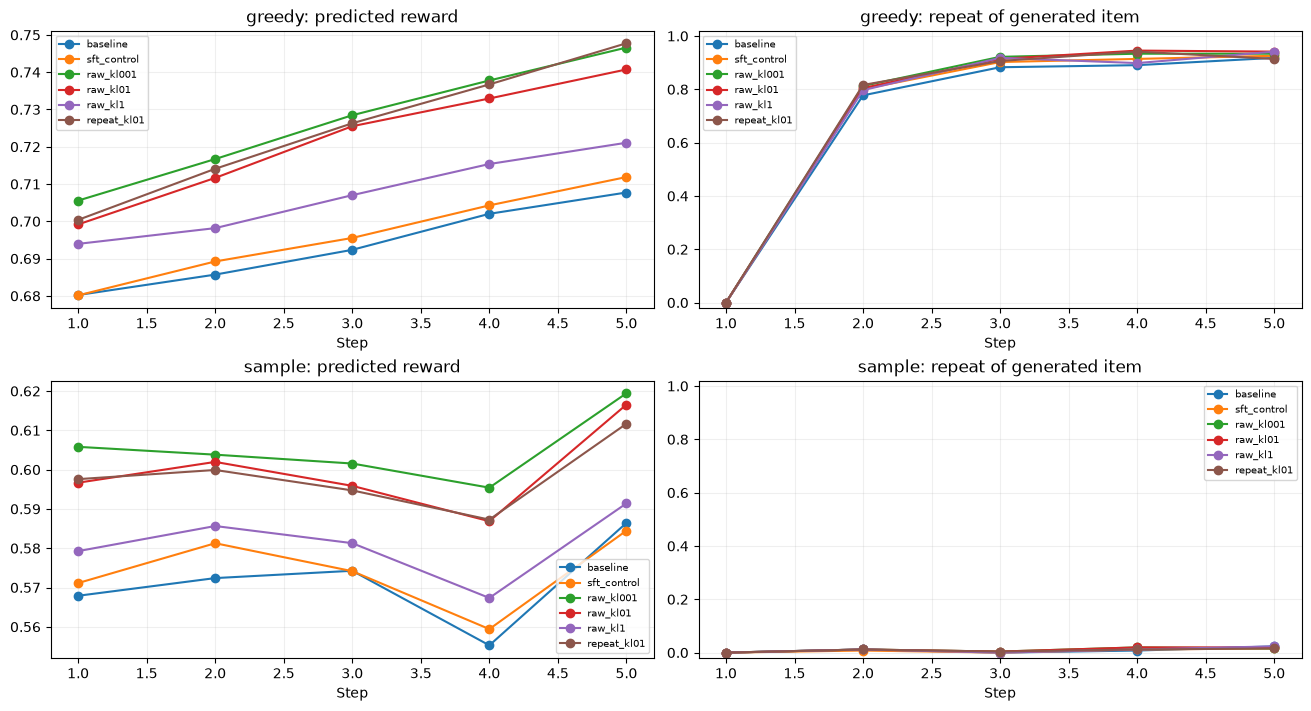

In [15]:
if final:
    fig,axes=plt.subplots(2,2,figsize=(13,7),constrained_layout=True)
    for row,mode in enumerate(["greedy","sample"]):
        for model,modes in final["rollout"].items():
            value=modes[mode]
            axes[row,0].plot(range(1,6),value["reward"],marker="o",label=model)
            axes[row,1].plot(range(1,6),value["repeat_generated"],marker="o",label=model)
        axes[row,0].set(title=f"{mode}: predicted reward",xlabel="Step")
        axes[row,1].set(title=f"{mode}: repeat of generated item",xlabel="Step",ylim=(-.02,1.02))
    for ax in axes.flat:
        ax.grid(alpha=.2)
        ax.legend(fontsize=7)
    plt.show()

In [ ]:
EXAMPLE_MODEL = "raw_kl001"
EXAMPLE_MODE = "greedy"
examples=read_json(RUN_DIR / "reports/rollout_examples.json")
if examples:
    rows=[]
    for example in examples[EXAMPLE_MODEL][EXAMPLE_MODE]:
        row={"user_id":example["user_id"],"history": " → ".join(example["history_last10_titles"])}
        row.update({f"step_{i+1}":title for i,title in enumerate(example["generated_titles"])})
        rows.append(row)
    display(pd.DataFrame(rows))

,user_id,history,step_1,step_2,step_3,step_4,step_5
0,10240,Сплит → Облачный атлас → Женщина в Чёрном → Шрек → Матильда,Мстители: Финал,Гнев человеческий,Гнев человеческий,Гнев человеческий,Гнев человеческий
1,25818,"Полярный круг → Кости → Хрустальный → Кавалерия → Мой домашний динозавр → Подслушано → Человек, ...",Прабабушка легкого поведения,Прабабушка легкого поведения,Прабабушка легкого поведения,Прабабушка легкого поведения,Прабабушка легкого поведения
2,27740,Елена → Родина → Балто → Душа → Король лев (2019) → Вперёд → Принц Египта → Балерина,100% волк,100% волк,100% волк,100% волк,100% волк
3,35628,Воскресший Эртугрул → Нимфоманка. Фильм первый → Убийства по открыткам → Без компромиссов → Гнев...,Гнев человеческий,Гнев человеческий,Гнев человеческий,Гнев человеческий,Прабабушка легкого поведения
4,39813,[4k] Оперативная съемка → Заложница 3 → Приворот. Чёрное венчание → Кто не спрятался → Коридор б...,Гнев человеческий,Гнев человеческий,Прабабушка легкого поведения,Прабабушка легкого поведения,Прабабушка легкого поведения


## 8. Долгосрочная цель и ограничения данных

Возврат в течение семи дней рассмотрен как возможная proxy-цель. Используются только полные окна
наблюдения внутри временного split. Это **описательная статистика**, не эффект RL.

KION содержит агрегированные user–item записи с последней датой просмотра: полную ежедневную
активность восстановить нельзя. Для return reward нужны признаки, известные до решения, и будущий
возврат только как метка. Проверка реального влияния рекомендаций на удержание потребует онлайн-данных
или подходящих логов показов для обоснованной off-policy оценки.

In [15]:
if final and "return_proxy" in final:
    display(pd.DataFrame({split:final["return_proxy"][split]
                          for split in ["train","validation","test"]}).T.round(5))

,complete_window_user_days,return_7d_rate
train,228460.0,0.53022
validation,41342.0,0.48604
test,19929.0,0.47714


## 9. Выводы эксперимента

1. **Оптимизация proxy сработала.** На сохранённом запуске RL увеличил предсказанный reward сильнее,
   чем дополнительные supervised-обновления. Реальный досмотр для новых рекомендаций неизвестен.
2. **Релевантность изменилась мало по точечной оценке.** Bootstrap не установил значимого изменения
   NDCG основного варианта; это не доказывает эквивалентность или выполнение порога 5% на test.
3. **Reward model ограничивает выводы.** На test её RMSE хуже сглаженного среднего объекта, а средний
   отклик завышен. Улучшение proxy может включать использование ошибок модели; отдельно это не доказано.
4. **Greedy-цепочки вырождаются.** Повторы присутствуют уже у baseline. RL и текущий штраф не решают
   проблему; sampling даёт разнообразие, но его релевантность не следует из разнообразия автоматически.
5. **Долгосрочный эффект не установлен.** Возвраты описывают данные, а не изменение удержания из-за RL.

Границы применимости: активные warm-пользователи, train-каталог, один seed, короткий RL-запуск,
неполные истории и суточные даты. Длительность объектов отсутствует, поэтому гипотеза о предпочтении
короткого контента не проверена. Test после просмотра не используется для новой настройки моделей.

Для дальнейшей работы: несколько seeds, независимый аудит reward, проверка калибровки на последующих
периодах и обучение на контекстах с собственными сгенерированными действиями. Это направления следующих
экспериментов, а не объяснения, уже подтверждённые текущими данными.